# Previsão de Preço de Veículos — Tabela FIPE

**Projeto Final — Aplicação de Machine Learning Clássico**

Notebook construído seguindo a sequência do *Guia Prático de Machine Learning em Python — Complemento da Aula 2*:
ambiente e estrutura, entradas de dados, framing do problema, qualidade e engenharia de features,
validação, métricas e pipeline reproduzível.

**Base de dados:** fipeX — Dataset Completo da Tabela FIPE
`https://huggingface.co/datasets/joaosilva424/fipex-veiculos-brasil` — licença CC0-1.0

---
## 1. Preparação do ambiente e estrutura do projeto

*Guia, seção 1: primeiro organizamos o ambiente; depois escrevemos o modelo.*

In [ ]:
# Instala bibliotecas que podem nao estar presentes no ambiente padrao do Colab.
!pip -q install pyarrow joblib

# Bibliotecas centrais de manipulacao de dados.
import numpy as np                  # Vetores e operacoes numericas.
import pandas as pd                 # Tabelas (DataFrame) e leitura de arquivos.
import matplotlib.pyplot as plt     # Graficos.

# Mostra versoes uteis para registrar a reprodutibilidade do exercicio.
import sklearn
print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)
print("scikit-learn:", sklearn.__version__)

NumPy: 2.1.3
Pandas: 2.2.3
scikit-learn: 1.6.1


In [2]:
from pathlib import Path  # Facilita trabalhar com caminhos em Windows/Linux/Colab.

# Descobre a pasta atual do projeto.
BASE_DIR = Path.cwd()

# Define os diretorios principais uma unica vez.
RAW_DIR = BASE_DIR / "data" / "raw"
PROCESSED_DIR = BASE_DIR / "data" / "processed"
MODEL_DIR = BASE_DIR / "models"
OUTPUT_DIR = BASE_DIR / "outputs"

# Cria as pastas caso ainda nao existam.
for pasta in [RAW_DIR, PROCESSED_DIR, MODEL_DIR, OUTPUT_DIR]:
    pasta.mkdir(parents=True, exist_ok=True)

# Fixa a semente para permitir repetir o experimento.
SEED = 42

print("Projeto:", BASE_DIR)

Projeto: /content


---
## 2. Entrada de dados — Parquet

*Guia, seção 2.8: Parquet é colunar e eficiente, muito usado em pipelines modernos.*

O repositório oferece dumps por período de referência (`YYYY/MM/`). Usamos um único período
em vez do histórico completo (18,8 milhões de linhas) por duas razões:

1. O histórico repete o mesmo veículo a cada mês publicado — volume alto sem informação nova.
2. O card do dataset informa que os dumps por período são **imutáveis e reproduzíveis**,
   ao contrário da versão consolidada. Isso atende ao checklist de reprodutibilidade (guia, 12.2).

In [3]:
# Dump da FIPE referente a um unico periodo de referencia.
URL = "https://huggingface.co/datasets/joaosilva424/fipex-veiculos-brasil/resolve/main/2026/01/fipex-prices.parquet"

# Le a tabela Parquet diretamente da origem.
df = pd.read_parquet(URL)

# Guarda uma copia local: dados originais nunca devem ser sobrescritos.
df.to_parquet(RAW_DIR / "fipex_2026_01.parquet", index=False)

# Confere o tamanho: (linhas, colunas).
print("Formato:", df.shape)

# Lista os nomes das colunas.
print(df.columns.tolist())

df.head()

Formato: (49676, 12)
['tipo_veiculo', 'codigo_fipe', 'nome_modelo', 'nome_marca', 'nome_combustivel', 'sigla_combustivel', 'ano_modelo', 'zero_km', 'valor_centavos', 'valor_formatado', 'mes_referencia', 'ano_referencia']


,tipo_veiculo,codigo_fipe,nome_modelo,nome_marca,nome_combustivel,sigla_combustivel,ano_modelo,zero_km,valor_centavos,valor_formatado,mes_referencia,ano_referencia
0,moto,840015-6,ATV 100,ADLY,Gasolina,g,2000.0,False,319700,"R$ 3.197,00",1,2026
1,moto,840015-6,ATV 100,ADLY,Gasolina,g,2001.0,False,340300,"R$ 3.403,00",1,2026
2,moto,840015-6,ATV 100,ADLY,Gasolina,g,2002.0,False,373200,"R$ 3.732,00",1,2026
3,moto,840014-8,ATV 50,ADLY,Gasolina,g,2000.0,False,240400,"R$ 2.404,00",1,2026
4,moto,840014-8,ATV 50,ADLY,Gasolina,g,2001.0,False,250900,"R$ 2.509,00",1,2026


In [4]:
# A base cobre carros, motos e caminhoes. O escopo do projeto sao automoveis.
print(df["tipo_veiculo"].value_counts())

# Filtra apenas automoveis e trabalha sobre uma copia independente.
carros = df[df["tipo_veiculo"] == "carro"].copy()

print("\nCarros:", carros.shape)

tipo_veiculo
carro       29871
caminhão    11205
moto         8600
Name: count, dtype: int64

Carros: (29871, 12)


---
## 3. Do problema real ao framing de Machine Learning

*Guia, seção 3: antes do algoritmo, vem a pergunta — qual decisão o modelo precisa apoiar?*

### 3.1 Cartão do problema

| Campo do cartão | Preenchimento |
|---|---|
| Contexto/objetivo | Estimar o valor de referência de veículos ainda não tabelados pela FIPE |
| Variável-alvo | `valor_centavos` convertido para reais e transformado em logaritmo |
| Tipo de tarefa | Regressão |
| Stakeholders | Concessionárias, seguradoras, consumidor final |
| Métrica de negócio | Erro percentual na precificação de veículos sem referência |
| Métrica técnica | MAPE como principal; MAE, RMSE e R² como apoio |
| Restrições | Interpretabilidade desejável; risco de vazamento por repetição de veículo |

### 3.2 O risco central deste problema

A FIPE é uma **tabela de referência**, não um registro de transações. Cada veículo aparece
várias vezes, uma por ano-modelo. Uma divisão aleatória entre treino e teste colocaria o
"Corolla 2019" no treino e o "Corolla 2020" no teste — praticamente o mesmo objeto, com preços
quase idênticos. O modelo memorizaria o vizinho em vez de aprender a formação do preço.

Isso é uma forma de vazamento por **repetição de entidade**. O tratamento correto é agrupar
por `codigo_fipe` na divisão dos dados (seção 7).

---
## 4. Qualidade dos dados

*Guia, seção 9.1: garbage in, garbage out — o modelo não corrige dados mal definidos.*

In [5]:
# Numero de valores ausentes por coluna.
print("Ausentes:")
print(carros.isna().sum())

# Quantidade de linhas duplicadas.
print("\nDuplicadas:", carros.duplicated().sum())

# Cardinalidade das variaveis categoricas.
print("\nCodigos FIPE distintos:", carros["codigo_fipe"].nunique())
print("Marcas distintas:", carros["nome_marca"].nunique())
print("Faixa de ano_modelo:", carros["ano_modelo"].min(), "a", carros["ano_modelo"].max())

Ausentes:
tipo_veiculo           0
codigo_fipe            0
nome_modelo            0
nome_marca             0
nome_combustivel       0
sigla_combustivel      0
ano_modelo           955
zero_km                0
valor_centavos         0
valor_formatado        0
mes_referencia         0
ano_referencia         0
dtype: int64

Duplicadas: 0

Codigos FIPE distintos: 7203
Marcas distintas: 104
Faixa de ano_modelo: 1985.0 a 2026.0


In [6]:
# Investiga a causa dos ausentes em ano_modelo antes de decidir a imputacao.
print(carros[carros["ano_modelo"].isna()]["zero_km"].value_counts())
print()
print(carros["zero_km"].value_counts())

zero_km
True    955
Name: count, dtype: int64

zero_km
False    28916
True       955
Name: count, dtype: int64


**Diagnóstico:** todos os registros sem `ano_modelo` são veículos zero quilômetro. A FIPE não
atribui ano-modelo a eles. Não é sujeira de dados — é ausência com causa conhecida, e por isso a
imputação pelo ano de referência é justificada, e não uma escolha arbitrária de mediana.

count      29871.00
mean      150862.77
std       427362.47
min         1802.00
25%        23992.00
50%        53450.00
75%       124268.50
max      9327230.00
Name: valor_reais, dtype: float64


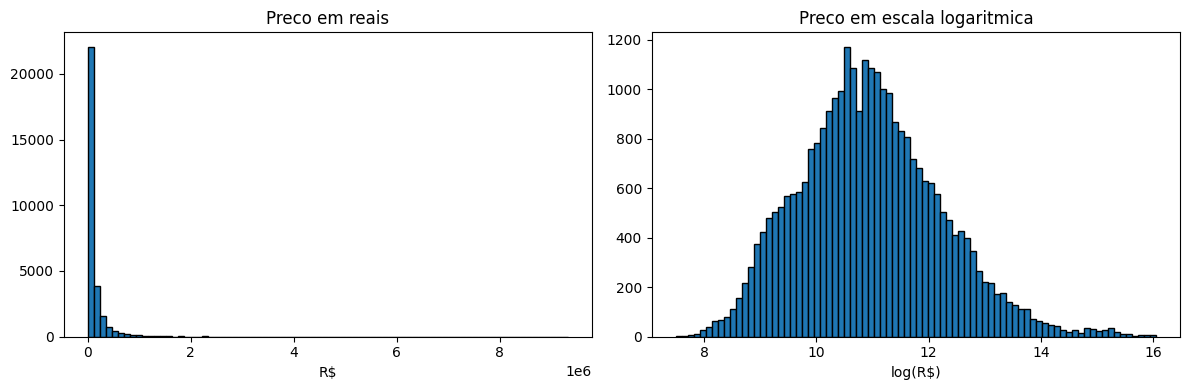

In [7]:
# Resumo do alvo em reais.
carros["valor_reais"] = carros["valor_centavos"] / 100
print(carros["valor_reais"].describe().round(2))

# Distribuicao do alvo antes e depois da transformacao logaritmica.
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].hist(carros["valor_reais"], bins=80, edgecolor="black")
ax[0].set_title("Preco em reais")
ax[0].set_xlabel("R$")
ax[1].hist(np.log(carros["valor_reais"]), bins=80, edgecolor="black")
ax[1].set_title("Preco em escala logaritmica")
ax[1].set_xlabel("log(R$)")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "distribuicao_alvo.png", dpi=120)
plt.show()

**Justificativa da transformação logarítmica:** a média do preço é aproximadamente três vezes
a mediana, indicando forte assimetria à direita. Além disso, a depreciação de um veículo é
multiplicativa — perde-se um percentual ao ano, não um valor fixo. No espaço logarítmico essa
relação se torna aproximadamente linear, o que é a condição em que a Regressão Linear opera bem.

---
## 5. Engenharia de features

*Guia, seção 9: transformar o dado bruto em variáveis que o modelo consiga usar.*

A base traz apenas cinco atributos diretamente utilizáveis. A especificação técnica do veículo,
porém, está codificada em texto livre dentro de `nome_modelo`:

`"CRUZE LT 1.8 16V Flex 4p Aut."`

Extraímos daí motorização, válvulas, portas, câmbio, turbo e tração.

In [8]:
# ano_modelo ausente ocorre apenas em zero km: imputa com o ano de referencia da tabela.
carros["ano_modelo"] = carros["ano_modelo"].fillna(carros["ano_referencia"])

# Idade do veiculo em anos. Substitui ano_modelo para evitar colinearidade perfeita:
# como ha um unico periodo de referencia, idade = 2026 - ano_modelo.
carros["idade"] = carros["ano_referencia"] - carros["ano_modelo"]

# Motorizacao em litros: padrao "1.8", "2.0", "3.5".
carros["motor"] = carros["nome_modelo"].str.extract(r"(\d\.\d)").astype(float)
carros["motor_informado"] = carros["motor"].notna().astype(int)

# Numero de portas: padrao "4p", "5 p". O \b inicial evita capturar o digito
# de nomes como "S10 P-Up", que produzia o valor invalido 0.
carros["portas"] = carros["nome_modelo"].str.extract(r"\b(\d)\s?[pP]\b").astype(float)
carros.loc[~carros["portas"].between(2, 5), "portas"] = np.nan
carros["portas_informado"] = carros["portas"].notna().astype(int)

# Valvulas: padrao "8V", "16V", "24V". Restringe aos valores tecnicamente validos.
carros["valvulas"] = carros["nome_modelo"].str.extract(r"(\d{1,2})\s?V\b").astype(float)
carros.loc[~carros["valvulas"].isin([8, 12, 16, 20, 24, 32]), "valvulas"] = np.nan
carros["valvulas_informado"] = carros["valvulas"].notna().astype(int)

# Indicadores binarios extraidos do texto.
carros["turbo"] = carros["nome_modelo"].str.contains(r"\bTB\b|Turbo", case=False).astype(int)
carros["tracao_4x4"] = carros["nome_modelo"].str.contains(r"4x4|AWD|4WD", case=False).astype(int)

# Cambio em tres classes: a ausencia da informacao e tratada como categoria propria,
# nao como manual, porque a FIPE simplesmente omite o dado em muitos registros.
carros["cambio"] = np.select(
    [carros["nome_modelo"].str.contains(r"Aut\.|Automat|CVT|DSG|Tiptronic", case=False),
     carros["nome_modelo"].str.contains(r"Mec\.|Manual", case=False)],
    ["automatico", "manual"],
    default="nao_informado"
)

print("Cobertura da extracao:")
for col in ["motor_informado", "portas_informado", "valvulas_informado"]:
    print(f"  {col:22s} {carros[col].mean():.1%}")
print()
print(carros["cambio"].value_counts())

Cobertura da extracao:
  motor_informado        88.9%
  portas_informado       28.5%
  valvulas_informado     41.8%

cambio
nao_informado    20159
automatico        7407
manual            2305
Name: count, dtype: int64


In [9]:
# Veiculos eletricos nao possuem cilindrada: o valor correto e zero, e ele e conhecido,
# nao ausente. Sem esta correcao a imputacao pela mediana atribuiria um motor 2.0 a um eletrico.
eletrico = carros["nome_combustivel"] == "Eletrico"
if eletrico.sum() == 0:
    eletrico = carros["nome_combustivel"].str.contains("trico", case=False, na=False)
carros.loc[eletrico, "motor"] = 0.0
carros.loc[eletrico, "motor_informado"] = 1

# Os ausentes restantes em motor, portas e valvulas NAO sao preenchidos aqui.
# A mediana calculada com a base inteira usaria informacao do conjunto de teste;
# por isso a imputacao fica dentro do pipeline (secao 8), aprendida so no treino.

# Converte o booleano para inteiro e define o alvo em escala logaritmica.
carros["zero_km"] = carros["zero_km"].astype(int)
carros["log_valor"] = np.log(carros["valor_reais"])

# Salva a base tratada.
carros.to_parquet(PROCESSED_DIR / "carros_tratado.parquet", index=False)

print("Eletricos corrigidos:", int(eletrico.sum()))
print("Ausentes a imputar no pipeline:")
print(carros[["motor", "portas", "valvulas"]].isna().sum())

Eletricos corrigidos: 615
Ausentes a imputar no pipeline:
motor        2718
portas      21364
valvulas    17388
dtype: int64


---
## 6. Definição de X e y

*Guia, seção 3.2: do framing para X e y — a variável-alvo é definida explicitamente.*

In [10]:
# Variavel-alvo.
TARGET = "log_valor"

# Features numericas.
NUM = ["idade", "motor", "portas", "valvulas", "turbo", "tracao_4x4", "zero_km",
       "motor_informado", "portas_informado", "valvulas_informado"]

# Features categoricas.
CAT = ["nome_marca", "nome_combustivel", "cambio"]

# ano_modelo, valor_formatado e valor_centavos ficam de fora:
# os dois ultimos sao o proprio alvo em outra representacao (vazamento direto).
X = carros[NUM + CAT]
y = carros[TARGET]
grupos = carros["codigo_fipe"]

print("Entradas:", X.shape)
print("Alvo:", y.describe().round(3).to_dict())

Entradas: (29871, 13)
Alvo: {'count': 29871.0, 'mean': 10.954, 'std': 1.263, 'min': 7.497, '25%': 10.085, '50%': 10.887, '75%': 11.73, 'max': 16.048}


---
## 7. Divisão treino/teste sem vazamento

*Guia, seção 9.2: leakage é um erro silencioso.*

O guia trata do vazamento temporal (uma feature que só existe depois do evento) e alerta, no
Problema 6, contra o split aleatório em séries temporais. O caso desta base é uma terceira forma:
**repetição de entidade**. O mesmo `codigo_fipe` aparece em vários anos-modelo.

`GroupShuffleSplit` garante que todas as linhas de um veículo fiquem inteiras de um lado só,
de modo que o conjunto de teste contenha apenas veículos **inéditos** para o modelo.

In [11]:
from sklearn.model_selection import GroupShuffleSplit

# Divide 80/20 agrupando por codigo FIPE.
gss = GroupShuffleSplit(n_splits=1, test_size=0.20, random_state=SEED)
tr, te = next(gss.split(X, y, groups=grupos))

print("Treino:", len(tr), "linhas |", grupos.iloc[tr].nunique(), "veiculos")
print("Teste: ", len(te), "linhas |", grupos.iloc[te].nunique(), "veiculos")

# Verificacao explicita: nenhum veiculo pode aparecer nos dois conjuntos.
interseccao = set(grupos.iloc[tr]) & set(grupos.iloc[te])
print("Veiculos em ambos os conjuntos:", len(interseccao))

Treino: 23863 linhas | 5762 veiculos
Teste:  6008 linhas | 1441 veiculos
Veiculos em ambos os conjuntos: 0


---
## 8. Pipeline de pré-processamento

*Guia, seção 9.3: engenharia de features sem vazamento — o `ColumnTransformer` aplica
transformações diferentes a grupos diferentes de colunas, e o `Pipeline` garante que a
imputação e a padronização sejam aprendidas somente no treino.*

A imputação dos ausentes em `motor`, `portas` e `valvulas` é feita aqui, com `SimpleImputer`:
a mediana é calculada apenas nas linhas de treino e reaplicada no teste. Calculá-la antes da
divisão seria um vazamento, ainda que pequeno.

São dois pré-processamentos:

- **`pre`** (Modelo A, linear): imputa e padroniza as numéricas e aplica one-hot nas categóricas.
- **`pre_polinomial(grau)`** (Modelo B, polinomial): além disso, gera potências e produtos
  das variáveis contínuas (`idade`, `motor`, `portas`, `valvulas`). Com grau 2, por exemplo,
  surgem `idade²`, `motor²` e `idade × motor`. As variáveis binárias (0/1) ficam de fora da
  expansão, porque elevar 0 ou 1 ao quadrado não muda nada.

In [12]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler, PolynomialFeatures

# Imputa os ausentes pela mediana do treino e padroniza as numericas: a padronizacao
# e necessaria para a regressao linear interpretar coeficientes em escala comparavel.
# min_frequency agrupa marcas raras em uma categoria unica, evitando centenas de
# colunas com pouquissimas amostras.
pre = ColumnTransformer([
    ("num", Pipeline([
        ("imp", SimpleImputer(strategy="median")),
        ("esc", StandardScaler())
    ]), NUM),
    ("cat", OneHotEncoder(handle_unknown="ignore", min_frequency=10), CAT)
])

# Variaveis continuas recebem os termos polinomiais; as binarias (0/1) nao,
# porque 0^2 = 0 e 1^2 = 1 apenas duplicariam a coluna.
CONT = ["idade", "motor", "portas", "valvulas"]
BIN = [c for c in NUM if c not in CONT]

def pre_polinomial(grau):
    # PolynomialFeatures gera potencias e produtos ate o grau pedido.
    # Grau 2 sobre [idade, motor]: idade, motor, idade^2, idade*motor, motor^2.
    # A imputacao vem antes (o polinomio nao aceita ausentes) e a padronizacao
    # depois, para os termos novos ficarem em escala comparavel.
    return ColumnTransformer([
        ("poli", Pipeline([
            ("imp", SimpleImputer(strategy="median")),
            ("poly", PolynomialFeatures(degree=grau, include_bias=False)),
            ("esc", StandardScaler())
        ]), CONT),
        ("bin", StandardScaler(), BIN),
        ("cat", OneHotEncoder(handle_unknown="ignore", min_frequency=10), CAT)
    ])

print("Colunas geradas com grau 2:",
      pre_polinomial(2).fit(X.iloc[tr]).get_feature_names_out()[:14].tolist())

Colunas geradas com grau 2: ['poli__idade', 'poli__motor', 'poli__portas', 'poli__valvulas', 'poli__idade^2', 'poli__idade motor', 'poli__idade portas', 'poli__idade valvulas', 'poli__motor^2', 'poli__motor portas', 'poli__motor valvulas', 'poli__portas^2', 'poli__portas valvulas', 'poli__valvulas^2']


---
## 9. Modelos A e B

- **Modelo A — Regressão Linear Múltipla** (Aula 6): interpretável, fornece o efeito
  de cada atributo sobre o preço. Assume que cada efeito é uma reta: o carro perde o mesmo
  percentual de valor no 1º e no 15º ano.
- **Modelo B — Regressão Polinomial**: a mesma regressão linear, aplicada sobre as features
  expandidas com potências e produtos (seção 8). Isso permite curvas — a depreciação pode ser
  mais forte nos primeiros anos e desacelerar depois — e interações, como o efeito da idade
  depender da motorização.

O modelo continua "linear nos coeficientes": o algoritmo de ajuste é o mesmo `LinearRegression`,
só que recebendo colunas como `idade²` e `idade × motor`.

### 9.1 Escolha do grau do polinômio

Grau alto demais faz a curva se contorcer para passar pelos pontos do treino (overfitting).
O grau é escolhido por **validação cruzada dentro do treino**, com `GroupKFold`, para que o
conjunto de teste continue intocado até a avaliação final. Grau 1 equivale ao Modelo A.

In [13]:
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import GroupKFold, cross_val_score

# Validacao cruzada agrupada por veiculo, usando somente as linhas de treino.
gkf = GroupKFold(n_splits=5)

r2_por_grau = {}
for grau in [1, 2, 3, 4]:
    pipe = Pipeline([("pre", pre_polinomial(grau)), ("mod", LinearRegression())])
    scores = cross_val_score(pipe, X.iloc[tr], y.iloc[tr], cv=gkf,
                             groups=grupos.iloc[tr], scoring="r2")
    r2_por_grau[grau] = scores.mean()
    print(f"grau {grau}: R2 medio = {scores.mean():.4f}  (desvio {scores.std():.4f})")

# Fica com o grau de maior R2 medio na validacao.
GRAU = max(r2_por_grau, key=r2_por_grau.get)
print("\nGrau escolhido:", GRAU)

grau 1: R2 medio = 0.9079  (desvio 0.0048)


grau 2: R2 medio = 0.9096  (desvio 0.0043)


grau 3: R2 medio = 0.9096  (desvio 0.0048)


grau 4: R2 medio = 0.9101  (desvio 0.0052)

Grau escolhido: 4


In [14]:
from sklearn.base import clone
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import time

def treinar_avaliar(nome, pre_proc, algoritmo):
    # Une pre-processamento e algoritmo em um unico objeto treinavel.
    # clone cria uma copia nova do pre-processamento, para que um modelo nao
    # reaproveite o objeto ja ajustado por outro.
    modelo = Pipeline([("pre", clone(pre_proc)), ("mod", algoritmo)])

    # fit aprende somente com o conjunto de treino.
    inicio = time.time()
    modelo.fit(X.iloc[tr], y.iloc[tr])
    duracao = time.time() - inicio

    # Previsao no espaco logaritmico e retorno para reais.
    pred_log = modelo.predict(X.iloc[te])
    real = np.exp(y.iloc[te])
    prev = np.exp(pred_log)

    resultado = {
        "modelo": nome,
        "R2_log": r2_score(y.iloc[te], pred_log),
        "MAE_R$": mean_absolute_error(real, prev),
        "RMSE_R$": np.sqrt(mean_squared_error(real, prev)),
        "MAPE_%": np.mean(np.abs((real - prev) / real)) * 100,
        "treino_s": duracao
    }
    return modelo, resultado

modelo_lin, res_lin = treinar_avaliar("Regressao Linear", pre, LinearRegression())
modelo_poly, res_poly = treinar_avaliar(f"Regressao Polinomial (grau {GRAU})",
                                        pre_polinomial(GRAU), LinearRegression())

comparativo = pd.DataFrame([res_lin, res_poly]).set_index("modelo")
print(comparativo.round(3))
comparativo.to_csv(OUTPUT_DIR / "comparativo_modelos.csv")

                               R2_log     MAE_R$     RMSE_R$  MAPE_%  treino_s
modelo                                                                        
Regressao Linear                0.916  47031.234  235513.462  27.582     0.099
Regressao Polinomial (grau 4)   0.918  44502.068  181196.308  28.017     0.137


---
## 10. Métricas de avaliação

*Guia, seção 11.2.*

| Métrica | Interpretação neste projeto |
|---|---|
| MAE | Erro médio em reais. Fácil de comunicar ao usuário final. |
| RMSE | Penaliza erros grandes. Muito acima do MAE indica presença de outliers. |
| R² | Proporção da variância do log do preço explicada pelo modelo. |
| MAPE | Erro percentual. **Métrica principal**, porque errar R$ 3 mil é grave num veículo popular e irrelevante num veículo de luxo. |

O R² é calculado no espaço logarítmico, onde o modelo é treinado; MAE, RMSE e MAPE são
convertidos de volta para reais, que é a unidade do problema real.

---
## 11. Análise de resíduos

Em regressão, o diagnóstico equivalente à matriz de confusão é a análise de resíduos.
*Guia, Problema 5: analisar resíduos por subgrupos; Problema 4, extensão: calcular o erro
relativo por faixa de preço.*

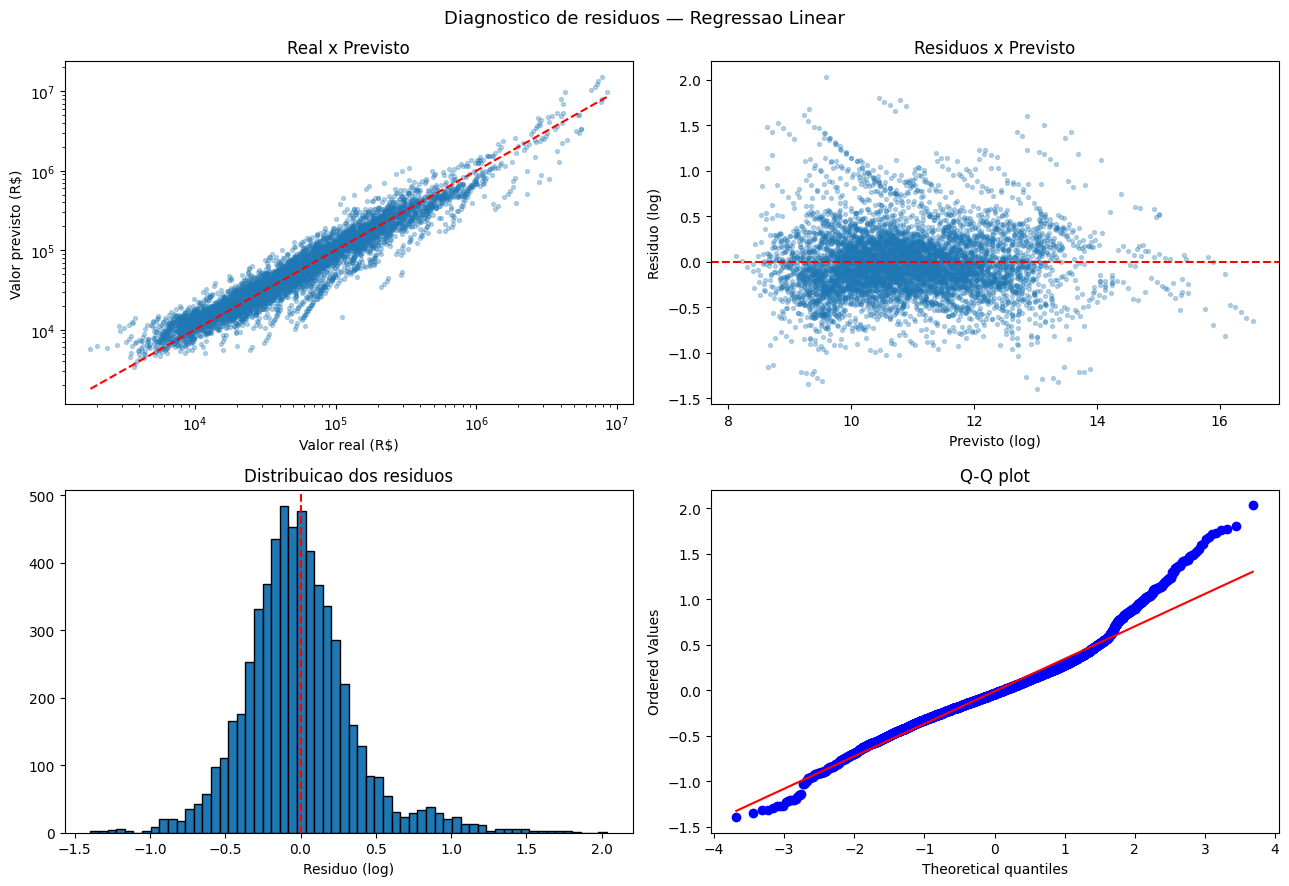

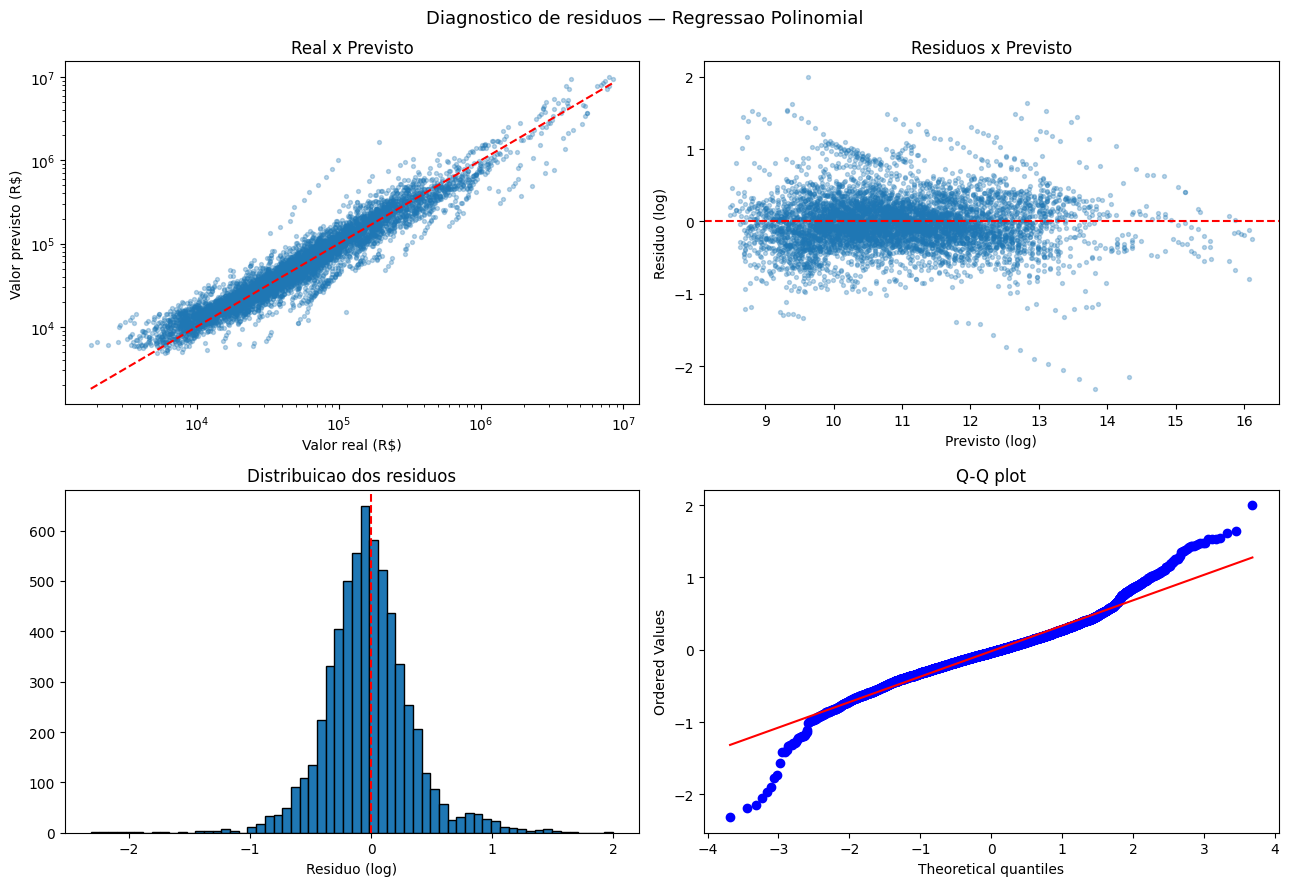

In [15]:
from scipy import stats

def diagnostico(modelo, nome):
    y_log = y.iloc[te]
    pred_log = modelo.predict(X.iloc[te])
    real, prev = np.exp(y_log), np.exp(pred_log)
    resid = y_log - pred_log

    fig, ax = plt.subplots(2, 2, figsize=(13, 9))
    fig.suptitle(f"Diagnostico de residuos — {nome}", fontsize=13)

    # Real x previsto: a previsao perfeita ficaria sobre a diagonal.
    ax[0,0].scatter(real, prev, alpha=0.3, s=8)
    ax[0,0].plot([real.min(), real.max()], [real.min(), real.max()], "r--")
    ax[0,0].set_xscale("log"); ax[0,0].set_yscale("log")
    ax[0,0].set_xlabel("Valor real (R$)"); ax[0,0].set_ylabel("Valor previsto (R$)")
    ax[0,0].set_title("Real x Previsto")

    # Residuos x previsto: um funil ou curva indica ma especificacao do modelo.
    ax[0,1].scatter(pred_log, resid, alpha=0.3, s=8)
    ax[0,1].axhline(0, color="r", linestyle="--")
    ax[0,1].set_xlabel("Previsto (log)"); ax[0,1].set_ylabel("Residuo (log)")
    ax[0,1].set_title("Residuos x Previsto")

    # Distribuicao dos residuos: idealmente centrada em zero e simetrica.
    ax[1,0].hist(resid, bins=60, edgecolor="black")
    ax[1,0].axvline(0, color="r", linestyle="--")
    ax[1,0].set_xlabel("Residuo (log)")
    ax[1,0].set_title("Distribuicao dos residuos")

    # Q-Q plot: verifica a normalidade dos residuos.
    stats.probplot(resid, dist="norm", plot=ax[1,1])
    ax[1,1].set_title("Q-Q plot")

    plt.tight_layout()
    plt.savefig(OUTPUT_DIR / f"residuos_{nome.lower().replace(' ', '_')}.png", dpi=120)
    plt.show()

    return pd.DataFrame({
        "real": np.asarray(real),
        "prev": np.asarray(prev),
        "erro_pct": np.asarray((prev - real) / real * 100),
        "marca": carros.iloc[te]["nome_marca"].values,
        "idade": carros.iloc[te]["idade"].values
    })

diag_lin = diagnostico(modelo_lin, "Regressao Linear")
diag_poly = diagnostico(modelo_poly, "Regressao Polinomial")

In [16]:
def erro_por_faixa(diag, nome):
    d = diag.copy()
    # Divide o conjunto de teste em cinco faixas de preco de tamanho igual.
    d["faixa"] = pd.qcut(d["real"], 5,
                         labels=["Muito baixo", "Baixo", "Medio", "Alto", "Muito alto"])
    tab = d.groupby("faixa", observed=True).agg(
        n=("real", "size"),
        preco_mediano=("real", "median"),
        # MAPE: magnitude do erro, independente do sinal.
        mape=("erro_pct", lambda s: s.abs().mean()),
        # Vies: se positivo, o modelo superestima aquela faixa.
        vies=("erro_pct", "mean")
    ).round(1)
    print(f"\n=== {nome} ===")
    print(tab)
    return tab

tab_lin = erro_por_faixa(diag_lin, "Regressao Linear")
tab_poly = erro_por_faixa(diag_poly, "Regressao Polinomial")
tab_poly.to_csv(OUTPUT_DIR / "erro_por_faixa_polinomial.csv")


=== Regressao Linear ===
                n  preco_mediano  mape  vies
faixa                                       
Muito baixo  1202        11366.0  35.7  28.8
Baixo        1201        27366.0  23.2   6.4
Medio        1202        52356.5  23.5   1.2
Alto         1201        98338.0  25.8   4.4
Muito alto   1202       291842.5  29.6  -2.5

=== Regressao Polinomial ===
                n  preco_mediano  mape  vies
faixa                                       
Muito baixo  1202        11366.0  36.7  30.1
Baixo        1201        27366.0  21.9   5.6
Medio        1202        52356.5  24.5   2.9
Alto         1201        98338.0  26.8   6.2
Muito alto   1202       291842.5  30.2  -0.1


In [17]:
# Marcas com maior erro percentual: normalmente as de baixo volume na base.
print(diag_poly.groupby("marca")["erro_pct"]
      .agg(n="size", mape=lambda s: s.abs().mean())
      .query("n >= 30").sort_values("mape", ascending=False).head(10).round(1))

                   n  mape
marca                     
Suzuki            55  55.6
Land Rover       154  50.7
Ferrari           38  48.5
Asia Motors       35  48.5
Porsche          162  45.2
VW - VolksWagen  530  37.6
JAC               31  34.3
BMW              268  33.1
Mercedes-Benz    384  32.5
Jaguar            77  30.8


---
## 12. Importância dos atributos

*Escopo do projeto, item: analisar a contribuição dos atributos (Feature Importance).*

No modelo polinomial, um atributo aparece espalhado em vários termos (`idade`, `idade²`,
`idade × motor`...), então olhar um coeficiente isolado engana. Usamos a **importância por
permutação**: embaralhamos uma coluna original por vez no conjunto de teste e medimos quanto
o R² cai. Se o modelo piora muito sem a informação correta daquela coluna, ela é importante.

idade                 1.1384
valvulas              0.6851
motor                 0.5868
nome_marca            0.2654
nome_combustivel      0.0403
portas                0.0149
motor_informado       0.0089
turbo                 0.0068
portas_informado      0.0055
cambio                0.0008
zero_km               0.0006
tracao_4x4            0.0003
valvulas_informado    0.0001
dtype: float64


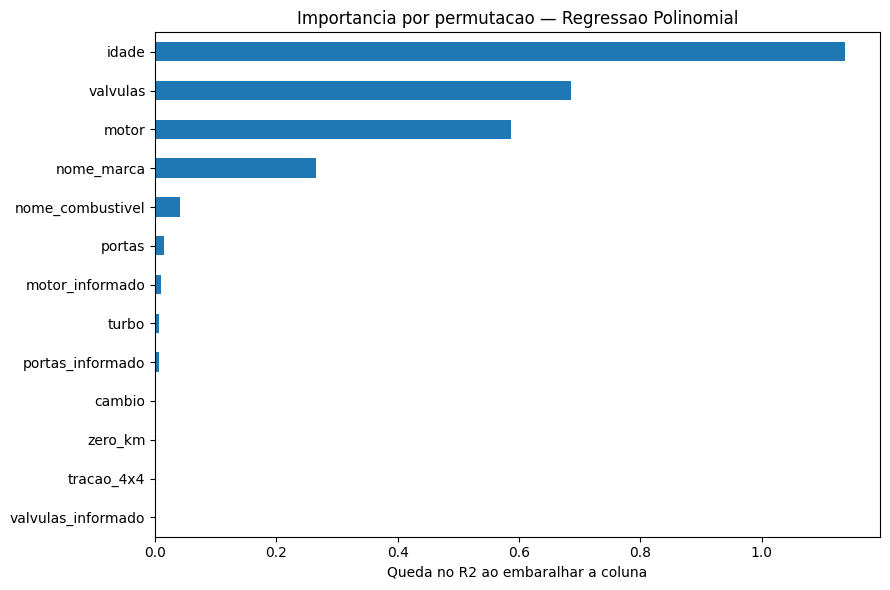

In [18]:
from sklearn.inspection import permutation_importance

# Embaralha cada coluna original do teste 5 vezes e mede a queda media do R2.
# Como atua nas colunas originais, idade e seus termos derivados contam juntos.
perm = permutation_importance(modelo_poly, X.iloc[te], y.iloc[te],
                              n_repeats=5, random_state=SEED, scoring="r2")

importancias = pd.Series(perm.importances_mean, index=X.columns).sort_values(ascending=False)
print(importancias.round(4))

importancias.sort_values().plot(kind="barh", figsize=(9, 6))
plt.title("Importancia por permutacao — Regressao Polinomial")
plt.xlabel("Queda no R2 ao embaralhar a coluna")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "importancia_features.png", dpi=120)
plt.show()

**Como ler este gráfico — cuidado com `valvulas`.** A importância por permutação mede o quanto
o modelo **depende** de uma coluna, e não o quanto ela influencia o preço na realidade.

- **Quedas maiores que 1** (caso de `idade`) significam que o R² ficou negativo: com termos
  como `idade⁴`, uma idade embaralhada produz previsões absurdas, piores que chutar a média.
- **`valvulas` aparece em segundo lugar**, embora só 42% dos veículos tenham essa informação
  no nome. Ela entra multiplicada por idade e motor nos termos polinomiais; ao embaralhá-la,
  surgem combinações irreais (ex.: 8 válvulas com motor 5.0) e o polinômio extrapola.
  É um efeito da forma do modelo, não evidência de que válvulas pesem tanto no preço.

A leitura segura é a ordem geral: idade, motorização e marca são o que o modelo mais usa;
câmbio, tração e zero km pouco acrescentam.

In [19]:
# Coeficientes da regressao linear, no espaco log do preco.
# - Numericas: foram padronizadas, entao o coeficiente e o efeito de 1 desvio padrao
#   da variavel, e nao de 1 unidade. Abaixo, a idade e convertida para "por ano".
# - Marcas (one-hot): exp(coef) e o fator que multiplica o preco. Como todas as marcas
#   entram no one-hot junto com o intercepto, o fator nao tem uma marca de referencia
#   fixa; o que se compara com seguranca e uma marca contra outra.
# - A leitura "coeficiente = variacao percentual" so vale para coeficientes pequenos.
coefs = pd.Series(
    modelo_lin.named_steps["mod"].coef_,
    index=modelo_lin.named_steps["pre"].get_feature_names_out()
).sort_values()

tabela = pd.DataFrame({"coef": coefs, "fator_preco": np.exp(coefs)}).round(3)
print("Maior efeito negativo:")
print(tabela.head(8))
print("\nMaior efeito positivo:")
print(tabela.tail(8))

# Efeito de 1 ano de idade: divide o coeficiente pelo desvio padrao usado na padronizacao.
escala = modelo_lin.named_steps["pre"].named_transformers_["num"].named_steps["esc"]
coef_ano = coefs["num__idade"] / escala.scale_[NUM.index("idade")]
print(f"\nCada ano de idade multiplica o preco por {np.exp(coef_ano):.3f} "
      f"({(np.exp(coef_ano) - 1) * 100:.1f}% ao ano).")

# Exemplo de comparacao entre marcas: quantas vezes o preco muda, mantido o resto igual.
razao = np.exp(coefs["cat__nome_marca_Ferrari"] - coefs["cat__nome_marca_Porsche"])
print(f"Ferrari x Porsche, mesmas demais caracteristicas: {razao:.2f} vezes o preco.")

Maior efeito negativo:
                              coef  fator_preco
cat__nome_marca_Bugre       -1.435        0.238
cat__nome_marca_SHINERAY    -1.129        0.323
cat__nome_marca_Asia Motors -1.022        0.360
cat__nome_marca_Baby        -0.991        0.371
num__idade                  -0.922        0.398
cat__nome_marca_CHANA       -0.912        0.402
cat__nome_marca_Fibravan    -0.820        0.441
cat__nome_marca_Mahindra    -0.790        0.454

Maior efeito positivo:
                               coef  fator_preco
cat__nome_marca_Engesa        1.058        2.881
cat__nome_marca_Maserati      1.192        3.294
cat__nome_marca_Porsche       1.230        3.422
cat__nome_marca_ASTON MARTIN  1.655        5.232
cat__nome_marca_Rolls-Royce   2.072        7.937
cat__nome_marca_Mclaren       2.197        8.994
cat__nome_marca_Ferrari       2.669       14.431
cat__nome_marca_LAMBORGHINI   3.132       22.915

Cada ano de idade multiplica o preco por 0.916 (-8.4% ao ano).
Ferrari x Porsch

---
## 13. Validação cruzada

*Guia, seção 10.2: k-fold para estimar estabilidade.*

O `cross_val_score` do guia usa folds aleatórios. Aqui isso quebraria o agrupamento por veículo
e produziria uma estimativa otimista. Usamos `GroupKFold`, que preserva a restrição definida
na seção 7.

In [20]:
from sklearn.model_selection import cross_val_score, GroupKFold

gkf = GroupKFold(n_splits=5)

for nome, pre_proc in [("Regressao Linear", pre),
                       (f"Polinomial (grau {GRAU})", pre_polinomial(GRAU))]:
    pipe = Pipeline([("pre", pre_proc), ("mod", LinearRegression())])
    scores = cross_val_score(pipe, X, y, cv=gkf, groups=grupos, scoring="r2", n_jobs=-1)
    print(f"{nome:24s} R2 por fold: {np.round(scores, 4)}")
    print(f"{'':24s} media={scores.mean():.4f}  desvio={scores.std():.4f}\n")

Regressao Linear         R2 por fold: [0.923  0.904  0.9075 0.9057 0.9144]
                         media=0.9109  desvio=0.0070



Polinomial (grau 4)      R2 por fold: [0.9262 0.9091 0.9107 0.9058 0.917 ]
                         media=0.9138  desvio=0.0072



---
## 14. Overfitting e underfitting

*Guia, seção 10.1: treino alto não garante generalização.*

Na regressão polinomial, a complexidade é o **grau**. Grau baixo pode não capturar a curva
de depreciação (underfitting); grau alto passa a ajustar ruído do treino (overfitting).
A tabela abaixo apenas **ilustra** esse efeito com o conjunto de teste — a escolha do grau
foi feita antes, na seção 9.1, sem olhar o teste.

In [21]:
# Compara desempenho em treino e teste para polinomios de grau crescente.
print(f"{'grau':>6} | {'n_features':>10} | {'R2 treino':>10} | {'R2 teste':>10}")
print("-" * 46)

for grau in [1, 2, 3, 4, 5]:
    pipe = Pipeline([("pre", pre_polinomial(grau)), ("mod", LinearRegression())])
    pipe.fit(X.iloc[tr], y.iloc[tr])
    n_features = len(pipe.named_steps["pre"].get_feature_names_out())
    r2_tr = r2_score(y.iloc[tr], pipe.predict(X.iloc[tr]))
    r2_te = r2_score(y.iloc[te], pipe.predict(X.iloc[te]))
    print(f"{grau:>6} | {n_features:>10} | {r2_tr:>10.4f} | {r2_te:>10.4f}")

  grau | n_features |  R2 treino |   R2 teste
----------------------------------------------
     1 |         98 |     0.9137 |     0.9160
     2 |        108 |     0.9158 |     0.9190


     3 |        128 |     0.9169 |     0.9202
     4 |        163 |     0.9183 |     0.9181


     5 |        219 |     0.9196 |     0.8726


---
## 15. Persistência do modelo

*Guia, seção 12.1, exemplo 28B: salvar o pipeline completo — pré-processamento e modelo.
Salvar apenas o estimador faria a inferência futura receber os dados em uma representação
diferente da usada no treinamento.*

In [22]:
import joblib

# Salva o pipeline completo: ColumnTransformer (com termos polinomiais) + regressao.
caminho = MODEL_DIR / "modelo_fipe_polinomial.joblib"
joblib.dump(modelo_poly, caminho)

# Demonstra que o arquivo pode ser carregado novamente.
modelo_carregado = joblib.load(caminho)
exemplo = X.iloc[te].head(3)
print("Previsto (R$):", np.round(np.exp(modelo_carregado.predict(exemplo)), 2))
print("Real     (R$):", np.round(np.exp(y.iloc[te].head(3)).values, 2))

Previsto (R$): [2139928.9 2330190.4  989449. ]
Real     (R$): [4085826. 4432658.  745875.]


In [23]:
# Registra o ambiente para reprodutibilidade (guia, secao 12.2).
# Grava cada biblioteca com a versao exata instalada, para repetir o experimento.
from importlib.metadata import version

pacotes = ["pandas", "numpy", "matplotlib", "scikit-learn", "pyarrow", "scipy", "joblib"]
requisitos = "".join(f"{p}=={version(p)}\n" for p in pacotes)
(BASE_DIR / "requirements.txt").write_text(requisitos)

print("requirements.txt:")
print(requisitos)
print("Origem dos dados:", URL)
print("Licenca: CC0-1.0")
print("Semente fixada:", SEED)
print("Linhas apos filtro:", len(carros))
print("Veiculos distintos:", carros["codigo_fipe"].nunique())

requirements.txt:
pandas==2.2.3
numpy==2.0.2
matplotlib==3.9.4
scikit-learn==1.6.1
pyarrow==21.0.0
scipy==1.13.1
joblib==1.5.3

Origem dos dados: https://huggingface.co/datasets/joaosilva424/fipex-veiculos-brasil/resolve/main/2026/01/fipex-prices.parquet
Licenca: CC0-1.0
Semente fixada: 42
Linhas apos filtro: 29871
Veiculos distintos: 7203


---
## 16. Checklist de reprodutibilidade

*Guia, seção 12.2.*

| Item | Situação |
|---|---|
| Registrar origem e versão do dataset | Dump imutável `2026/01`, licença CC0 |
| Fixar `random_state` | `SEED = 42` no split e na importância por permutação |
| Separar treino/teste antes das transformações | `GroupShuffleSplit` antes do `fit`; imputação pela mediana dentro do pipeline |
| Usar `Pipeline`/`ColumnTransformer` | Imputação, padronização, termos polinomiais e one-hot dentro do pipeline |
| Salvar parâmetros, métricas e versões | `outputs/`, `models/`, `requirements.txt` com versões exatas |
| Documentar a variável-alvo | Seção 3.1 |
| Comparar com baseline simples | Regressão Linear como baseline da Regressão Polinomial |

## 17. Resultados e conclusão

| Modelo | R² (log) | MAE | RMSE | MAPE | R² validação cruzada |
|---|---|---|---|---|---|
| Regressão Linear | 0,916 | R$ 47.031 | R$ 235.513 | **27,6%** | 0,911 ± 0,007 |
| Regressão Polinomial (grau 4) | **0,918** | **R$ 44.502** | **R$ 181.196** | 28,0% | **0,914** ± 0,007 |

**A Regressão Polinomial não superou a linear de forma clara.** Ela reduziu o erro em reais —
o RMSE caiu 23%, sinal de que os erros grandes, concentrados nos veículos caros, diminuíram; na
faixa de preço mais alta o viés foi de −2,5% para praticamente zero. Mas no **MAPE, a métrica
principal**, ficou ligeiramente pior (28,0% contra 27,6%), porque piorou nos veículos baratos:
na faixa mais baixa, superestima o preço em cerca de 30%.

Na validação cruzada a diferença entre os modelos (0,003 de R²) é do tamanho do desvio entre os
folds, e a escolha do grau (seção 9.1) mostrou o mesmo: os graus 2, 3 e 4 praticamente empatam.
A interpretação é que **a transformação logarítmica do alvo já tornou a relação quase linear** —
a depreciação multiplicativa virou uma reta no espaço log, e sobra pouca curvatura para o
polinômio capturar. O que limita o modelo é a falta de **informação** (qual é o modelo exato do
veículo, como a depreciação varia por marca), não a forma da curva.

A seção 14 mostra o custo de ir além: no grau 5, o R² de treino continua subindo (0,920), mas o
de teste cai para 0,873 — overfitting típico de polinômios de grau alto.

**Recomendação:** para uso, a Regressão Linear é preferível — desempenho equivalente no MAPE,
menos parâmetros e coeficientes diretamente interpretáveis (cada ano de idade reduz o valor de
referência em cerca de 8,4%, mantidas as demais características; seção 12).

## 18. Discussão

*Guia, seção 13.1, parte 6: erros, riscos de leakage, limitações e proposta de melhoria.*

**Limitações da base.** A FIPE não registra quilometragem, estado de conservação, opcionais nem
região. O modelo estima o valor de referência de uma configuração, não o preço de um exemplar
específico.

**Natureza da fonte.** Os preços são publicados pela FIPE, não observados em transações. O modelo
aprende a lógica de precificação da tabela, e não diretamente o comportamento do mercado.

**Vazamento tratado.** A repetição do mesmo veículo em vários anos-modelo foi controlada pelo
agrupamento por `codigo_fipe`. Sem esse cuidado as métricas ficariam artificialmente altas.
A imputação pela mediana também foi colocada dentro do pipeline, para ser aprendida só no treino.

**Limitação do modelo.** Os termos polinomiais cobrem apenas as variáveis contínuas. O modelo
não aprende, por exemplo, que um carro de luxo deprecia em ritmo diferente de um popular,
pois não há interação entre marca e idade. Incluí-la multiplicaria o número de colunas.

**Proposta de melhoria.** Extrair a família do modelo (Gol, Corolla...) do `nome_modelo` como
feature e testar a interação marca × idade, que atacam diretamente a falta de informação
apontada na conclusão. Em outra frente, cruzar as previsões com anúncios reais de veículos
usados permitiria medir o desvio entre a referência e o preço praticado — um segundo problema,
de maior valor prático, que a FIPE sozinha não resolve.